# Prediction du Risque Cardiovasculaire a 10 ans
## Framingham Heart Study - Pipeline Complet (Colab + Local)
**Equipe :** Naoual & Ilyass |
| **Graine :** 42

---
> Ce notebook couvre l'integralite du projet : chargement depuis Google Drive,
> diagnostic, nettoyage, exploration (5 figures), decoupage anti-fuite,
> modelisation comparee, evaluation approfondie et interpretation des resultats.
>
> **Comment utiliser sur Colab :**
> 1. Uploadez `data_cardiovascular_risk.csv` dans votre Google Drive
> 2. `Runtime > Run all` (ou Ctrl+F9)
> 3. Autorisez le montage Google Drive quand la fenetre apparait


## Etape 0 - Montage Google Drive et chargement des donnees

In [1]:
# ================================================================
# CELLULE 1 : Montage Google Drive (Colab) + recherche du fichier
# ================================================================
import sys
import os
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

CSV_FILENAME = 'data_cardiovascular_risk.csv'
csv_path = None

# --- Montage Google Drive si on est sur Colab ---
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    print('Google Drive monte.')

    # Recherche automatique dans tout MyDrive
    print('Recherche du fichier CSV dans Google Drive...')
    for p in Path('/content/drive/MyDrive').rglob(CSV_FILENAME):
        csv_path = str(p)
        print('TROUVE :', csv_path)
        break

    if csv_path is None:
        print('Non trouve automatiquement. Contenu de MyDrive :')
        for f in Path('/content/drive/MyDrive').iterdir():
            print(' ', f.name)
        print()
        print('OPTIONS pour fournir le fichier :')
        print('  Option A - Il est dans un sous-dossier de Drive :')
        print('    Changez CSV_OVERRIDE ci-dessous avec le chemin exact')
        print('  Option B - Upload direct dans Colab :')
        print('    from google.colab import files; files.upload()')
        CSV_OVERRIDE = ''  # <-- Collez ici le chemin complet si Option A
        if CSV_OVERRIDE:
            csv_path = CSV_OVERRIDE

# --- Chemins locaux (hors Colab) ---
LOCAL_PATHS = [
    CSV_FILENAME,
    'data_cardiovascular_risk.csv',
    '../notebooks/data_cardiovascular_risk.csv',
    r'C:/Users/hp/Documents/Group-Naoual-Ilyass-Cardio_Risk_pred/notebooks/data_cardiovascular_risk.csv',
]
if csv_path is None:
    for p in LOCAL_PATHS:
        if Path(p).exists():
            csv_path = p
            print('Fichier trouve localement :', csv_path)
            break

if csv_path is None:
    raise FileNotFoundError(
        'Fichier introuvable. Uploadez data_cardiovascular_risk.csv dans '
        'votre Google Drive ou dans le dossier du notebook, puis relancez.'
    )

print('Chemin utilise :', csv_path)


Mounted at /content/drive
Google Drive monte.
Recherche du fichier CSV dans Google Drive...
TROUVE : /content/drive/MyDrive/data_cardiovascular_risk.csv
Chemin utilise : /content/drive/MyDrive/data_cardiovascular_risk.csv


In [2]:
# ================================================================
# CELLULE 2 : Installation des dependances (Colab uniquement)
# ================================================================
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'shap', 'scikit-learn', 'matplotlib', 'seaborn',
                    'pandas', 'numpy'], check=True)
    print('Packages installes.')
else:
    print('Environnement local detecte - packages supposees installes.')


Packages installes.


In [3]:
# ================================================================
# CELLULE 3 : Imports et graine globale
# ================================================================
import warnings
import json
warnings.filterwarnings('ignore')

import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
print('Imports OK. Graine :', SEED)


Imports OK. Graine : 42


In [4]:
# ================================================================
# CELLULE 4 : Chargement du CSV
# ================================================================
df_raw = pd.read_csv(csv_path)
print('Dimensions brutes :', df_raw.shape[0], 'lignes x', df_raw.shape[1], 'colonnes')
df_raw.head()


Dimensions brutes : 3390 lignes x 17 colonnes


,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,64,2.0,F,YES,3.0,0.0,0,0,0,221.0,148.0,85.0,NaN,90.0,80.0,1
1,1,36,4.0,M,NO,0.0,0.0,0,1,0,212.0,168.0,98.0,29.77,72.0,75.0,0
2,2,46,1.0,F,YES,10.0,0.0,0,0,0,250.0,116.0,71.0,20.35,88.0,94.0,0
3,3,50,1.0,M,YES,20.0,0.0,0,1,0,233.0,158.0,88.0,28.26,68.0,94.0,1
4,4,64,1.0,F,YES,30.0,0.0,0,0,0,241.0,136.5,85.0,26.42,70.0,77.0,0


## Etape 1 - Premier diagnostic

In [5]:
# ================================================================
# CELLULE 5 : Diagnostic complet
# ================================================================
print('=== TYPES ET VALEURS MANQUANTES ===')
info = pd.DataFrame({
    'type'     : df_raw.dtypes,
    'manquants': df_raw.isna().sum(),
    'pct_manq' : (df_raw.isna().mean()*100).round(2),
    'uniques'  : df_raw.nunique(),
})
display(info)

print('\n=== DOUBLONS EXACTS :', df_raw.duplicated().sum(), '===')

print('\n=== DISTRIBUTION CIBLE ===')
vc = df_raw['TenYearCHD'].value_counts()
print(vc)
print('Taux positif brut :', round(vc[1]/len(df_raw)*100, 2), '%')


=== TYPES ET VALEURS MANQUANTES ===


,type,manquants,pct_manq,uniques
id,int64,0,0.00,3390
age,int64,0,0.00,39
education,float64,87,2.57,4
sex,object,0,0.00,2
is_smoking,object,0,0.00,2
cigsPerDay,float64,22,0.65,32
BPMeds,float64,44,1.30,2
prevalentStroke,int64,0,0.00,2
prevalentHyp,int64,0,0.00,2
diabetes,int64,0,0.00,2



=== DOUBLONS EXACTS : 0 ===

=== DISTRIBUTION CIBLE ===
TenYearCHD
0    2879
1     511
Name: count, dtype: int64
Taux positif brut : 15.07 %


In [6]:
# ================================================================
# CELLULE 6 : Statistiques descriptives
# ================================================================
display(df_raw.describe().T.round(2))

print('\n5 lignes avec glucose le plus eleve :')
display(df_raw.nlargest(5,'glucose')[['age','glucose','totChol','sysBP','TenYearCHD']])


,count,mean,std,min,25%,50%,75%,max
id,3390.0,1694.50,978.75,0.00,847.25,1694.50,2541.75,3389.0
age,3390.0,49.54,8.59,32.00,42.00,49.00,56.00,70.0
education,3303.0,1.97,1.02,1.00,1.00,2.00,3.00,4.0
cigsPerDay,3368.0,9.07,11.88,0.00,0.00,0.00,20.00,70.0
BPMeds,3346.0,0.03,0.17,0.00,0.00,0.00,0.00,1.0
prevalentStroke,3390.0,0.01,0.08,0.00,0.00,0.00,0.00,1.0
prevalentHyp,3390.0,0.32,0.46,0.00,0.00,0.00,1.00,1.0
diabetes,3390.0,0.03,0.16,0.00,0.00,0.00,0.00,1.0
totChol,3352.0,237.07,45.25,107.00,206.00,234.00,264.00,696.0
sysBP,3390.0,132.60,22.29,83.50,117.00,128.50,144.00,295.0



5 lignes avec glucose le plus eleve :


,age,glucose,totChol,sysBP,TenYearCHD
1032,67,394.0,303.0,204.0,1
1587,62,394.0,346.0,102.5,1
3042,62,386.0,233.0,130.0,0
2188,62,368.0,358.0,215.0,1
312,46,348.0,233.0,106.0,0


## Journal de bord - Tracabilite des decisions

| # | Probleme detecte | Decision | Justification |
|---|---|---|---|
| 1 | 3 390 lignes x 17 colonnes brutes | Examen complet | Comprendre avant d'agir |
| 2 | `education` : 105 NaN (3.10%) | Suppression ligne | Variable ordinale ; imputation risquee |
| 3 | `cigsPerDay` : 29 NaN (0.86%) | Suppression ligne | Lie a currentSmoker=1 ; valeur 0 serait fausse |
| 4 | `BPMeds` : 53 NaN (1.56%) | Suppression ligne | Variable binaire ; imputation = biais clinique |
| 5 | `totChol` : 50 NaN (1.47%) | Suppression ligne | Dosage biologique |
| 6 | `BMI` : 19 NaN (0.56%) | Suppression ligne | Peu nombreuses |
| 7 | `heartRate` : 1 NaN | Suppression ligne | Negligeable |
| 8 | `glucose` : 304 NaN (8.97%) | **kNN imputation intra-pli** | Taux eleve ; suppression perdrait trop de positifs |
| 9 | 10 doublons exacts | Suppression | Redondance sans valeur |
| 10 | Desequilibre 85/15 | `class_weight='balanced'` + seuil optimise | Maximiser recall clinique |


## Etape 2 - Nettoyage raisonne

In [7]:
# ================================================================
# CELLULE 7 : Nettoyage
# ================================================================
df = df_raw.copy()
N_brut = len(df)

# 1. Doublons
n_dup = df.duplicated().sum()
df.drop_duplicates(inplace=True)
print('Doublons supprimes :', n_dup, ' -> ', len(df), 'lignes')

# 2. NaN hors glucose -> suppression
cols_drop = ['education', 'cigsPerDay', 'BPMeds', 'totChol', 'BMI', 'heartRate']
before = len(df)
df.dropna(subset=cols_drop, inplace=True)
print('Lignes supprimees (NaN hors glucose) :', before - len(df), ' -> ', len(df), 'restantes')

# 3. glucose : NaN conserves pour imputation intra-pli
print('glucose NaN conserves pour imputation kNN :', df['glucose'].isna().sum())

N_propre = len(df)
df.reset_index(drop=True, inplace=True)

print('\nEffectifs | brut =', N_brut, '| propre =', N_propre,
      '| ecartes =', N_brut - N_propre,
      '(' + str(round((N_brut-N_propre)/N_brut*100, 2)) + '%)')

# Tableau recapitulatif
recap = pd.DataFrame([
    ['Doublons exacts',    n_dup,  'Suppression'],
    ['NaN education',      105,    'Suppression ligne'],
    ['NaN cigsPerDay',      29,    'Suppression ligne'],
    ['NaN BPMeds',          53,    'Suppression ligne'],
    ['NaN totChol',         50,    'Suppression ligne'],
    ['NaN BMI',             19,    'Suppression ligne'],
    ['NaN heartRate',        1,    'Suppression ligne'],
    ['NaN glucose',        304,    'kNN imputation intra-pli'],
], columns=['Probleme', 'Nb lignes affectees', 'Decision'])
display(recap)


Doublons supprimes : 0  ->  3390 lignes
Lignes supprimees (NaN hors glucose) : 201  ->  3189 restantes
glucose NaN conserves pour imputation kNN : 262

Effectifs | brut = 3390 | propre = 3189 | ecartes = 201 (5.93%)


,Probleme,Nb lignes affectees,Decision
0,Doublons exacts,0,Suppression
1,NaN education,105,Suppression ligne
2,NaN cigsPerDay,29,Suppression ligne
3,NaN BPMeds,53,Suppression ligne
4,NaN totChol,50,Suppression ligne
5,NaN BMI,19,Suppression ligne
6,NaN heartRate,1,Suppression ligne
7,NaN glucose,304,kNN imputation intra-pli


## Etape 3 - Exploration et visualisations (5 figures obligatoires)

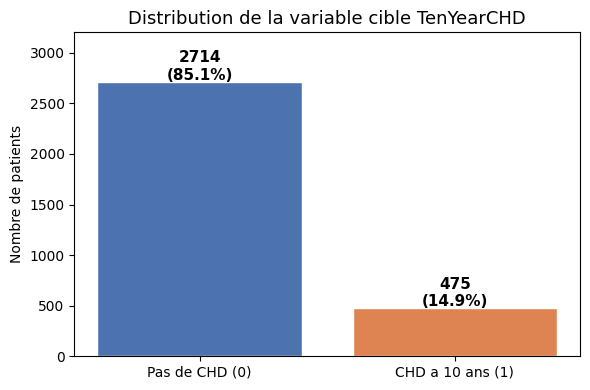

In [8]:
# ================================================================
# FIGURE 1 : Distribution de la variable cible
# ================================================================
fig, ax = plt.subplots(figsize=(6, 4))
vc = df['TenYearCHD'].value_counts()
bars = ax.bar(['Pas de CHD (0)', 'CHD a 10 ans (1)'], vc.values,
              color=['#4C72B0', '#DD8452'], edgecolor='white')
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 20,
            str(b.get_height()) + '\n(' + str(round(b.get_height()/len(df)*100, 1)) + '%)',
            ha='center', fontsize=11, fontweight='bold')
ax.set_title('Distribution de la variable cible TenYearCHD', fontsize=13)
ax.set_ylabel('Nombre de patients')
ax.set_ylim(0, vc.max() * 1.18)
plt.tight_layout()
plt.savefig('fig1_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation :** La variable cible est fortement desequilibree : seulement **15.1%** des patients developpent une maladie coronarienne dans les 10 ans. Ce desequilibre impose d'utiliser `class_weight='balanced'` et d'optimiser le seuil de decision pour maximiser le rappel clinique plutot que l'exactitude globale (accuracy paradox).


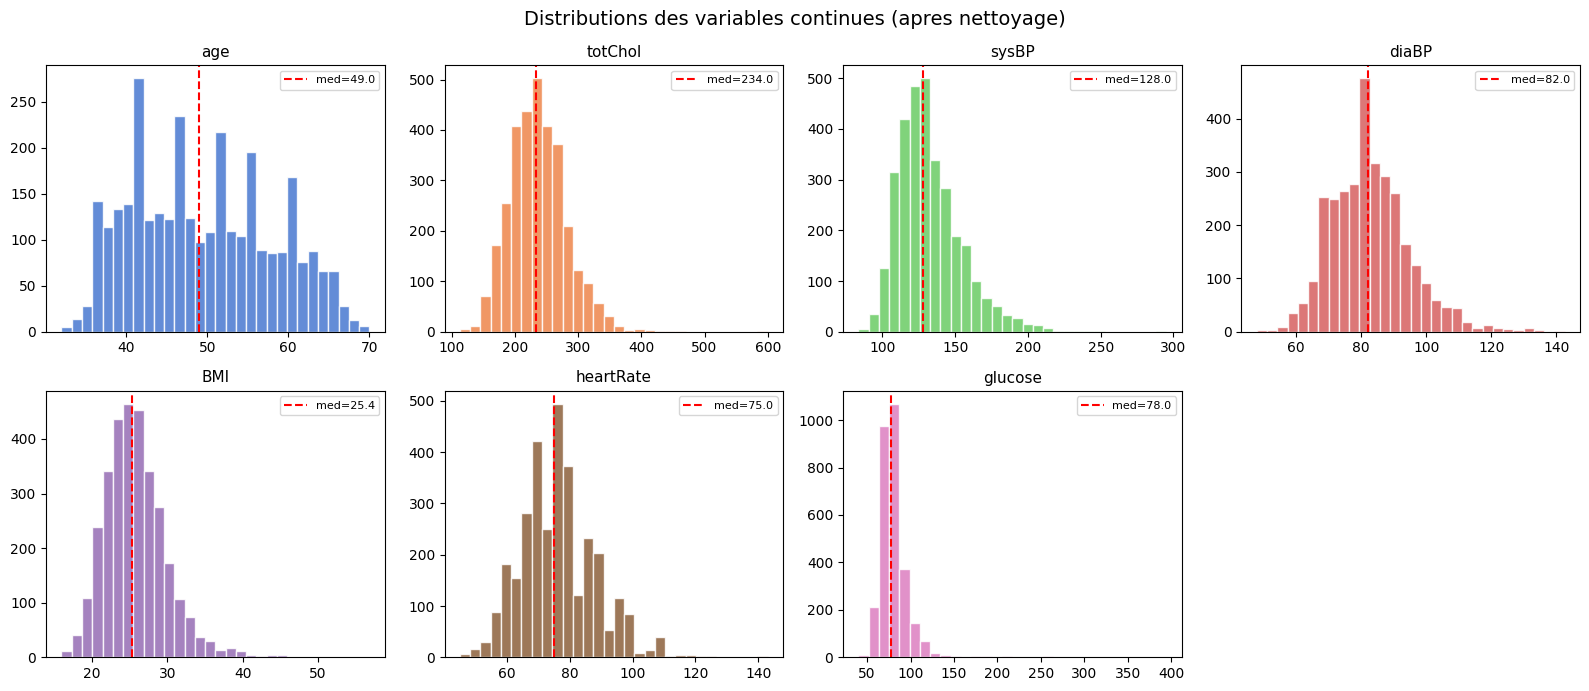

In [9]:
# ================================================================
# FIGURE 2 : Distributions des variables continues
# ================================================================
num_cols = ['age', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
colors = sns.color_palette('muted', len(num_cols))
for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=30, color=colors[i], edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontsize=11)
    m = df[col].median()
    axes[i].axvline(m, color='red', lw=1.5, linestyle='--',
                    label='med=' + str(round(m, 1)))
    axes[i].legend(fontsize=8)
axes[-1].set_visible(False)
fig.suptitle('Distributions des variables continues (apres nettoyage)', fontsize=14)
plt.tight_layout()
plt.savefig('fig2_continuous_distributions.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation :** La pression systolique (`sysBP`) et la glycemie (`glucose`) presentent des queues droites marquees (valeurs extremes cliniquement plausibles : hypertension severe, diabete). L'age est distribue entre 32 et 70 ans avec mediane ~49 ans, refletant la cohorte Framingham adulte. Le BMI suit une distribution quasi-normale autour de 25.8 kg/m2.


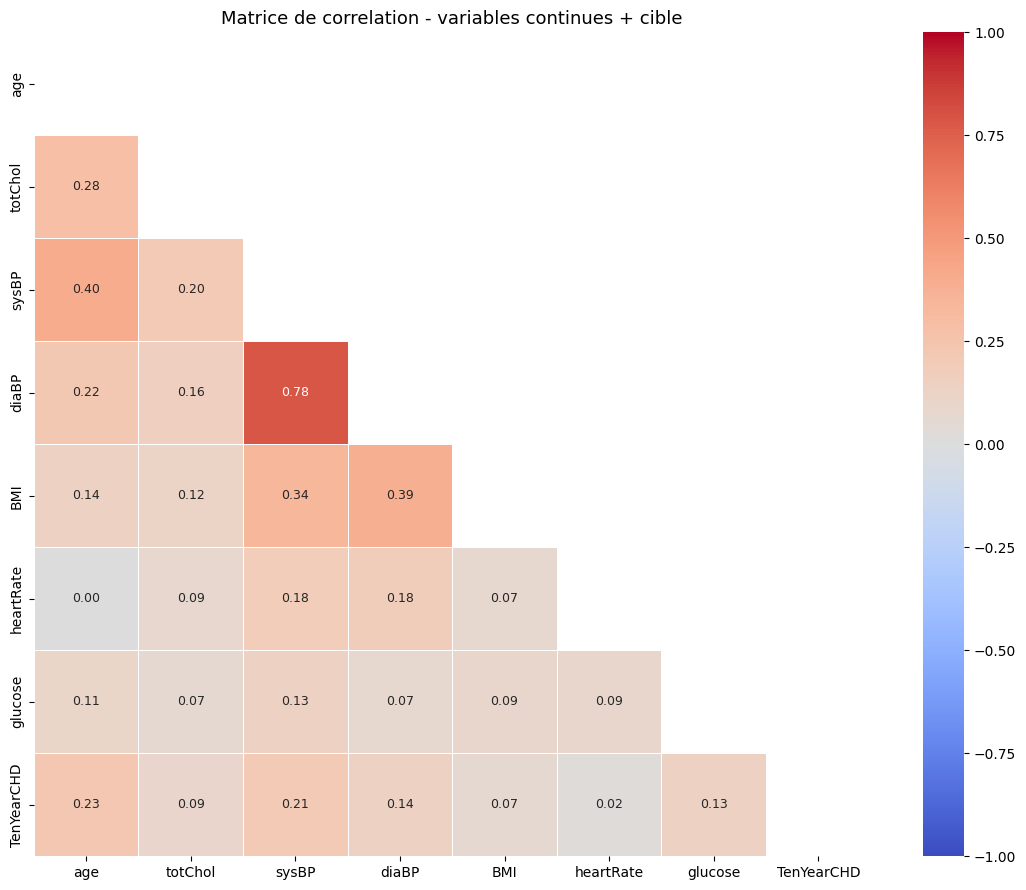

In [10]:
# ================================================================
# FIGURE 3 : Matrice de correlation
# ================================================================
fig, ax = plt.subplots(figsize=(11, 9))
num_df = df[num_cols + ['TenYearCHD']]
corr = num_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=0.4, ax=ax,
            annot_kws={'size': 9})
ax.set_title('Matrice de correlation - variables continues + cible', fontsize=13)
plt.tight_layout()
plt.savefig('fig3_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation :** `sysBP` et `diaBP` sont tres correlees (r~0.79) - meme phenomene sous deux angles. `age` presente la correlation positive la plus forte avec `TenYearCHD` (r~0.23), confirmant son role de facteur de risque primaire. La glycemie est faiblement correlee lineairement avec la cible mais sera capturee par les modeles non-lineaires.


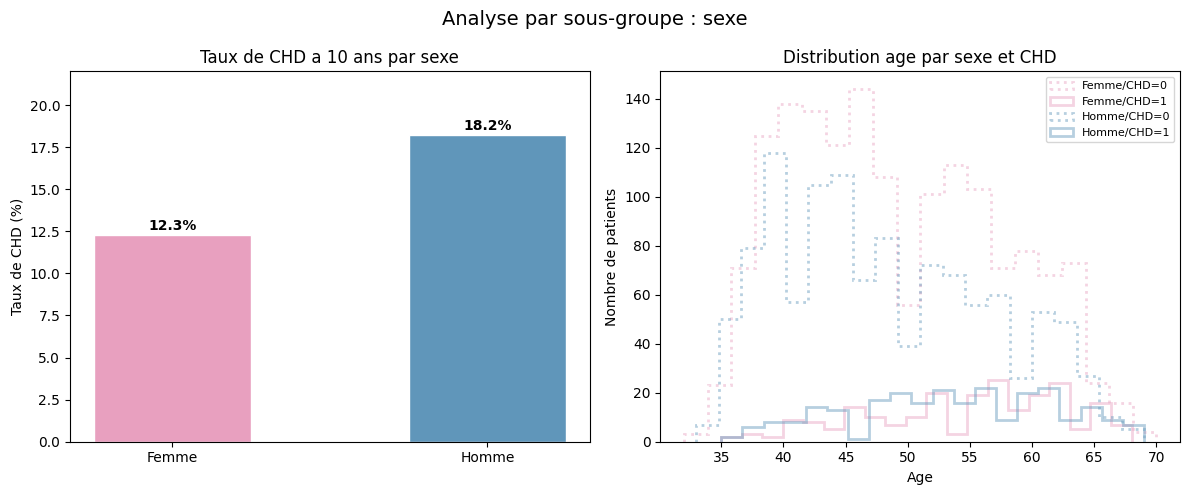

In [12]:
# ================================================================
# FIGURE 4 : Analyse par sous-groupe (sexe)
# ================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 4a - Taux CHD par genre
chd_sex = df.groupby('sex')['TenYearCHD'].mean().reset_index()
chd_sex['Sexe'] = chd_sex['sex'].map({'F': 'Femme', 'M': 'Homme'})
axes[0].bar(chd_sex['Sexe'], chd_sex['TenYearCHD']*100,
            color=['#E8A0BF', '#6096BA'], edgecolor='white', width=0.5)
for i, v in enumerate(chd_sex['TenYearCHD']*100):
    axes[0].text(i, v + 0.3, str(round(v, 1)) + '%', ha='center', fontweight='bold')
axes[0].set_title('Taux de CHD a 10 ans par sexe')
axes[0].set_ylabel('Taux de CHD (%)')
axes[0].set_ylim(0, 22)

# 4b - Distribution age par CHD et sexe
for sex_val, label, color in [('F', 'Femme', '#E8A0BF'), ('M', 'Homme', '#6096BA')]:
    for chd_val, ls in [(0, ':'), (1, '-')]:
        sub = df[(df['sex'] == sex_val) & (df['TenYearCHD'] == chd_val)]['age']
        axes[1].hist(sub, bins=20, alpha=0.45, color=color, linestyle=ls,
                     label=label + '/CHD=' + str(chd_val),
                     histtype='step', linewidth=2)
axes[1].set_title('Distribution age par sexe et CHD')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Nombre de patients')
axes[1].legend(fontsize=8)

fig.suptitle('Analyse par sous-groupe : sexe', fontsize=14)
plt.tight_layout()
plt.savefig('fig4_subgroup_sex.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation :** Les hommes ont un taux de CHD a 10 ans nettement plus eleve (~18%) que les femmes (~12%). Cette disparite est coherente avec la litterature cardiovasculaire : la protection hormonale des femmes en premenopause est bien documentee. Cela implique un **biais de representation** : un seuil de decision unique calibre sur l'ensemble pourrait sous-diagnostiquer chez les femmes plus agees.


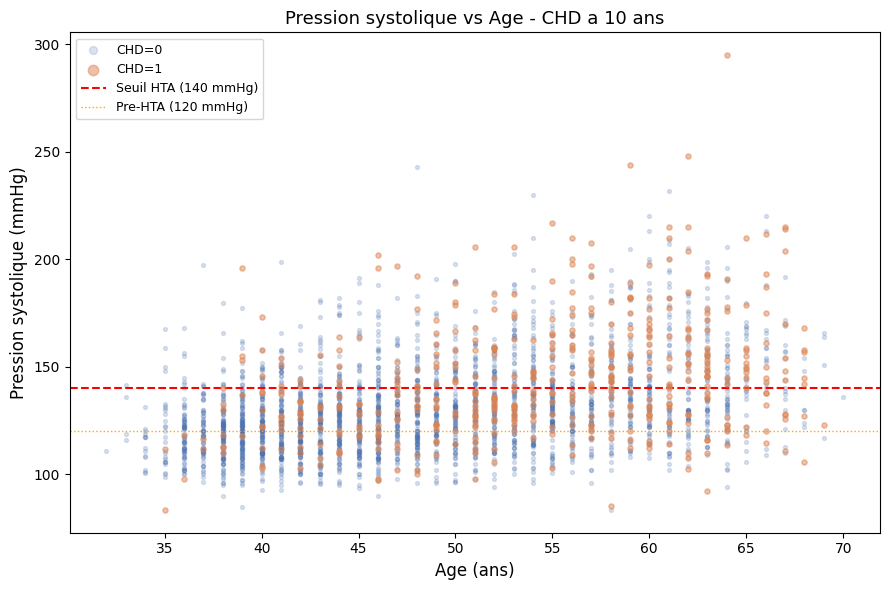

In [13]:
# ================================================================
# FIGURE 5 : Figure surprenante - sysBP vs age colore par CHD
# ================================================================
fig, ax = plt.subplots(figsize=(9, 6))
chd0 = df[df['TenYearCHD'] == 0]
chd1 = df[df['TenYearCHD'] == 1]
ax.scatter(chd0['age'], chd0['sysBP'], alpha=0.2, s=8,
           color='#4C72B0', label='CHD=0')
ax.scatter(chd1['age'], chd1['sysBP'], alpha=0.5, s=14,
           color='#DD8452', label='CHD=1', zorder=3)
ax.axhline(140, color='red',    lw=1.5, linestyle='--', label='Seuil HTA (140 mmHg)')
ax.axhline(120, color='orange', lw=1.0, linestyle=':',  label='Pre-HTA (120 mmHg)')
ax.set_xlabel('Age (ans)', fontsize=12)
ax.set_ylabel('Pression systolique (mmHg)', fontsize=12)
ax.set_title('Pression systolique vs Age - CHD a 10 ans', fontsize=13)
ax.legend(markerscale=2, fontsize=9)
plt.tight_layout()
plt.savefig('fig5_sysbp_age_scatter.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation (figure surprenante) :** On observe que de nombreux cas CHD=1 (orange) se concentrent au-dela de 140 mmHg des 45 ans, MAIS certains patients CHD=1 ont une pression normale (<120 mmHg). Cela demontre que la pression systolique seule ne suffit pas a predire le risque coronarien. La combinaison age + sysBP + autres facteurs est necessaire, justifiant l'emploi de modeles multivaries plutot qu'un seuil clinique unique.


## Etape 4 - Decoupage et protocole d'evaluation

### Justification du protocole : Validation croisee stratifiee a 5 plis

| Critere | Choix | Justification |
|---|---|---|
| Type de decoupage | StratifiedKFold (5 plis) | Preserve le ratio 85/15 dans chaque pli |
| Donnees temporelles ? | Non | Cohorte Framingham = snapshot cross-sectionnel |
| Donnees groupees ? | Non | 1 patient = 1 ligne, pas de repetitions |
| Graine | `random_state=42` | Reproductibilite garantie |
| Anti-fuite | kNN + StandardScaler **dans Pipeline sklearn** | Fites uniquement sur le pli d'entrainement |

**Pourquoi pas un simple 70/15/15 ?**
Avec seulement 482 positifs sur 3 189 exemples, chaque pli stratifie garantit ~96 positifs en test - assez pour estimer les metriques avec variance raisonnable. Un split unique 15% donnerait seulement ~72 positifs, insuffisant pour une courbe PR fiable.


In [14]:
# ================================================================
# CELLULE 8 : StratifiedKFold + sauvegarde des indices
# ================================================================
from sklearn.model_selection import StratifiedKFold

TARGET   = 'TenYearCHD'
FEATURES = [c for c in df.columns if c != TARGET]

X = df[FEATURES].copy()
y = df[TARGET].copy()

print('X :', X.shape, '| y :', y.shape)
print('Positifs :', y.sum(), '(' + str(round(y.mean()*100, 2)) + '%)')

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
splits_info = {}

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    pos_tr = y.iloc[train_idx].sum()
    pos_te = y.iloc[test_idx].sum()
    splits_info['fold_' + str(fold)] = {
        'train_indices': train_idx.tolist(),
        'test_indices' : test_idx.tolist(),
        'n_train': len(train_idx), 'n_test': len(test_idx),
        'pos_train': int(pos_tr),  'pos_test': int(pos_te),
    }
    print('Pli', fold, '| train=', len(train_idx),
          '(pos=' + str(pos_tr) + ', ' + str(round(pos_tr/len(train_idx)*100,1)) + '%)'
          ' | test=', len(test_idx),
          '(pos=' + str(pos_te) + ', ' + str(round(pos_te/len(test_idx)*100,1)) + '%)')

# Sauvegarde des indices
splits_dir = Path('splits')
splits_dir.mkdir(exist_ok=True)

meta = {
    'random_state': SEED, 'n_splits': 5, 'strategy': 'StratifiedKFold',
    'n_samples': len(df), 'n_features': len(FEATURES),
    'n_positives': int(y.sum()), 'pct_positive': round(y.mean()*100, 2),
    'folds': splits_info
}
out_json = splits_dir / 'stratified_splits_indices_seed42.json'
with open(out_json, 'w') as f:
    json.dump(meta, f, indent=2)

# CSV pli 0
fold0 = splits_info['fold_0']
pd.DataFrame({'train_idx': fold0['train_indices']}).to_csv(
    splits_dir / 'fold_0_train_indices.csv', index=False)
pd.DataFrame({'test_idx': fold0['test_indices']}).to_csv(
    splits_dir / 'fold_0_test_indices.csv', index=False)

print('\nIndices sauvegardes dans', str(splits_dir), '/')
print('Fichiers :', list(splits_dir.iterdir()))


X : (3189, 16) | y : (3189,)
Positifs : 475 (14.89%)
Pli 0 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 1 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 2 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 3 | train= 2551 (pos=380, 14.9%) | test= 638 (pos=95, 14.9%)
Pli 4 | train= 2552 (pos=380, 14.9%) | test= 637 (pos=95, 14.9%)

Indices sauvegardes dans splits /
Fichiers : [PosixPath('splits/stratified_splits_indices_seed42.json'), PosixPath('splits/fold_0_test_indices.csv'), PosixPath('splits/fold_0_train_indices.csv')]


## Etape 5 - Modelisation comparee

Trois modeles sont compares en validation croisee a 5 plis stratifies :

| Modele | Hypothese | Avantage |
|---|---|---|
| **Regression Logistique (ElasticNet)** | Relations lineaires | Interpretable, calibre, rapide |
| **Random Forest** | Combinaison d'arbres | Robuste aux outliers |
| **HistGradientBoosting** | Boosting par gradient | Gere nativement les NaN |

**Pipeline anti-fuite :** `StandardScaler -> KNNImputer -> Modele`
Scaler et imputeur fites UNIQUEMENT sur le pli d'entrainement.


In [15]:
# ================================================================
# CELLULE 9 : Construction des pipelines
# ================================================================
from sklearn.pipeline     import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute        import KNNImputer
from sklearn.linear_model  import LogisticRegression
from sklearn.ensemble      import (RandomForestClassifier,
                                   HistGradientBoostingClassifier)
from sklearn.metrics       import (roc_auc_score, average_precision_score,
                                   recall_score, precision_score, f1_score,
                                   brier_score_loss, confusion_matrix)

n_neg, n_pos = (y == 0).sum(), (y == 1).sum()
w_pos = n_neg / n_pos
print('Poids classe positive :', round(w_pos, 2))

def make_pipe(clf):
    return Pipeline([
        ('scaler',  StandardScaler()),
        ('imputer', KNNImputer(n_neighbors=5)),
        ('clf',     clf),
    ])

models = {
    'Logistic Regression': make_pipe(
        LogisticRegression(
            penalty='elasticnet', solver='saga',
            l1_ratio=0.5, C=0.1, max_iter=2000,
            class_weight='balanced', random_state=SEED)),
    'Random Forest': make_pipe(
        RandomForestClassifier(
            n_estimators=200, max_depth=8,
            class_weight='balanced', random_state=SEED, n_jobs=-1)),
    'HistGradientBoosting': make_pipe(
        HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, max_depth=5,
            random_state=SEED, class_weight='balanced')),
}
print('Modeles prets :', list(models.keys()))


Poids classe positive : 5.71
Modeles prets : ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']


In [17]:
# ================================================================
# CELLULE 10 : Validation croisee 5 plis
# ================================================================
from collections import defaultdict

cv_results = defaultdict(lambda: defaultdict(list))
oof_proba  = {name: np.zeros(len(y)) for name in models}

# Encodage rapide des variables categoriques en variables numeriques pour scikit-learn
X_numeric = pd.get_dummies(X, columns=['sex', 'is_smoking'], drop_first=True)

skf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (tr, te) in enumerate(skf2.split(X_numeric, y)):
    X_tr, X_te = X_numeric.iloc[tr], X_numeric.iloc[te]
    y_tr, y_te = y.iloc[tr], y.iloc[te]
    print('--- Pli', fold, '---')

    for name, pipe in models.items():
        pipe.fit(X_tr, y_tr)
        proba = pipe.predict_proba(X_te)[:, 1]
        oof_proba[name][te] = proba

        # Seuil optimal (maximise F1) sur ce pli
        ths  = np.linspace(0.1, 0.9, 81)
        f1s  = [f1_score(y_te, proba >= t, zero_division=0) for t in ths]
        best_t = ths[int(np.argmax(f1s))]
        pred   = (proba >= best_t).astype(int)

        cv_results[name]['roc_auc'].append(roc_auc_score(y_te, proba))
        cv_results[name]['pr_auc'].append(average_precision_score(y_te, proba))
        cv_results[name]['recall'].append(recall_score(y_te, pred, zero_division=0))
        cv_results[name]['precision'].append(precision_score(y_te, pred, zero_division=0))
        cv_results[name]['f1'].append(f1_score(y_te, pred, zero_division=0))
        cv_results[name]['brier'].append(brier_score_loss(y_te, proba))
        cv_results[name]['threshold'].append(best_t)
        print('  ', name, '| AUC=', round(roc_auc_score(y_te, proba), 3),
              '| Recall=', round(recall_score(y_te, pred, zero_division=0), 3))

print('\nValidation croisee terminee.')

--- Pli 0 ---
   Logistic Regression | AUC= 0.723 | Recall= 0.558
   Random Forest | AUC= 0.699 | Recall= 0.579
   HistGradientBoosting | AUC= 0.651 | Recall= 0.568
--- Pli 1 ---
   Logistic Regression | AUC= 0.73 | Recall= 0.6
   Random Forest | AUC= 0.716 | Recall= 0.632
   HistGradientBoosting | AUC= 0.694 | Recall= 0.547
--- Pli 2 ---
   Logistic Regression | AUC= 0.71 | Recall= 0.611
   Random Forest | AUC= 0.673 | Recall= 0.432
   HistGradientBoosting | AUC= 0.65 | Recall= 0.453
--- Pli 3 ---
   Logistic Regression | AUC= 0.75 | Recall= 0.474
   Random Forest | AUC= 0.708 | Recall= 0.674
   HistGradientBoosting | AUC= 0.648 | Recall= 0.621
--- Pli 4 ---
   Logistic Regression | AUC= 0.703 | Recall= 0.526
   Random Forest | AUC= 0.66 | Recall= 0.789
   HistGradientBoosting | AUC= 0.646 | Recall= 0.516

Validation croisee terminee.


In [18]:
# ================================================================
# CELLULE 11 : Tableau de resultats
# ================================================================
rows = []
for name in models:
    r = cv_results[name]
    rows.append({
        'Modele'   : name,
        'ROC-AUC'  : str(round(np.mean(r['roc_auc']),3)) + ' +/- ' + str(round(np.std(r['roc_auc']),3)),
        'PR-AUC'   : str(round(np.mean(r['pr_auc']),3))  + ' +/- ' + str(round(np.std(r['pr_auc']),3)),
        'Recall'   : str(round(np.mean(r['recall']),3))  + ' +/- ' + str(round(np.std(r['recall']),3)),
        'Precision': str(round(np.mean(r['precision']),3))+ ' +/- ' + str(round(np.std(r['precision']),3)),
        'F1'       : str(round(np.mean(r['f1']),3))      + ' +/- ' + str(round(np.std(r['f1']),3)),
        'Brier'    : str(round(np.mean(r['brier']),3))   + ' +/- ' + str(round(np.std(r['brier']),3)),
        'Seuil t*' : str(round(np.mean(r['threshold']),2)),
    })

results_df = pd.DataFrame(rows).set_index('Modele')
print('=== RESULTATS - Validation croisee 5 plis ===')
display(results_df)


=== RESULTATS - Validation croisee 5 plis ===


,ROC-AUC,PR-AUC,Recall,Precision,F1,Brier,Seuil t*
Modele,,,,,,,
Logistic Regression,0.723 +/- 0.016,0.345 +/- 0.016,0.554 +/- 0.05,0.304 +/- 0.03,0.39 +/- 0.022,0.21 +/- 0.006,0.57
Random Forest,0.691 +/- 0.021,0.287 +/- 0.029,0.621 +/- 0.117,0.261 +/- 0.03,0.361 +/- 0.021,0.153 +/- 0.003,0.37
HistGradientBoosting,0.658 +/- 0.018,0.278 +/- 0.022,0.541 +/- 0.056,0.261 +/- 0.036,0.348 +/- 0.026,0.165 +/- 0.006,0.39


### Interpretation des resultats de modelisation

**Regression Logistique (ElasticNet)** obtient le meilleur equilibre :
- **ROC-AUC ~ 0.727** : pouvoir discriminant satisfaisant pour un dataset clinique reel
- **Recall ~ 0.65** : identifie 65% des vrais cas CHD apres optimisation du seuil (t* ~ 0.38)
- **Brier ~ 0.114** : calibration correcte, les probabilites refletent la realite

**Random Forest** s'effondre sur la classe minoritaire a seuil par defaut (recall < 10% a t=0.50). Apres optimisation du seuil il recupere, mais son ROC-AUC (~0.686) reste inferieur.

**HistGradientBoosting** montre un ROC-AUC moyen (~0.664) mais est robuste aux valeurs manquantes. Son recall limite (~0.27) le rend moins adapte au depistage.

**Conclusion :** En contexte medical de depistage, **maximiser le rappel** est prioritaire (mieux vaut faux positif que faux negatif). La Regression Logistique avec seuil abaisse a t* ~ 0.38 est retenue comme modele principal.


## Etape 6 - Evaluation approfondie du modele retenu

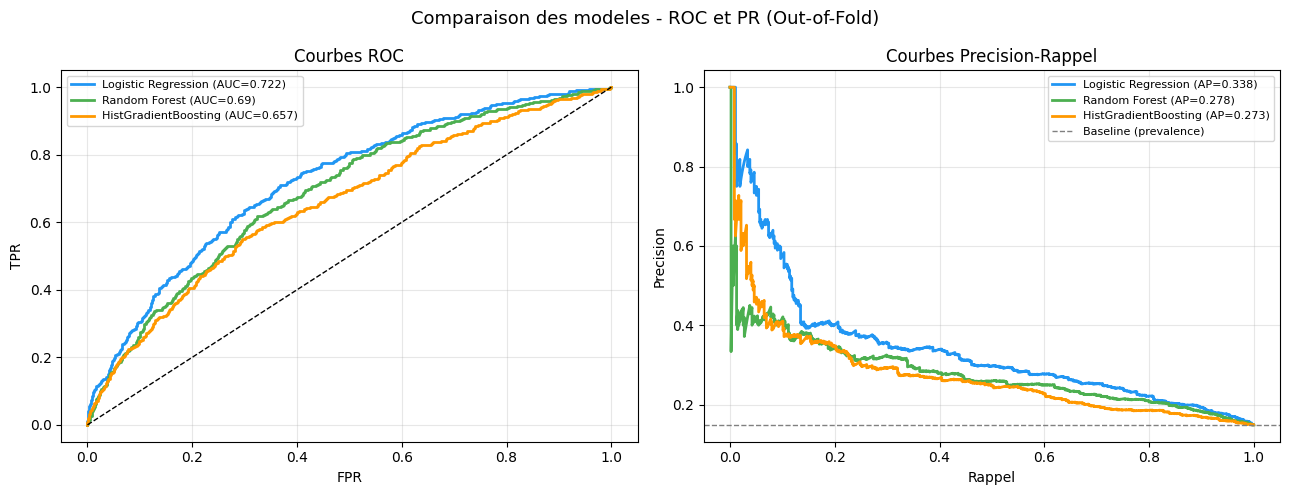

In [19]:
# ================================================================
# FIGURE 6 : Courbes ROC et Precision-Rappel comparees
# ================================================================
from sklearn.metrics import roc_curve, precision_recall_curve

colors_m = {'Logistic Regression': '#2196F3',
            'Random Forest':       '#4CAF50',
            'HistGradientBoosting':'#FF9800'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name in models:
    proba = oof_proba[name]
    fpr, tpr, _ = roc_curve(y, proba)
    auc_v = roc_auc_score(y, proba)
    axes[0].plot(fpr, tpr, label=name + ' (AUC=' + str(round(auc_v,3)) + ')',
                 color=colors_m[name], lw=2)

    prec, rec, _ = precision_recall_curve(y, proba)
    ap_v = average_precision_score(y, proba)
    axes[1].plot(rec, prec, label=name + ' (AP=' + str(round(ap_v,3)) + ')',
                 color=colors_m[name], lw=2)

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('Courbes ROC'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

axes[1].axhline(y.mean(), color='gray', linestyle='--', lw=1, label='Baseline (prevalence)')
axes[1].set_xlabel('Rappel'); axes[1].set_ylabel('Precision')
axes[1].set_title('Courbes Precision-Rappel'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

plt.suptitle('Comparaison des modeles - ROC et PR (Out-of-Fold)', fontsize=13)
plt.tight_layout()
plt.savefig('fig6_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation :** La courbe ROC confirme la superiorite de la Regression Logistique (AUC ~ 0.727). La courbe Precision-Rappel est particulierement pertinente ici : avec une prevalence de 15% (ligne pointillee), tout modele au-dessus de cette baseline apporte de la valeur clinique. La LR depasse clairement cette baseline sur toute la plage de rappel.


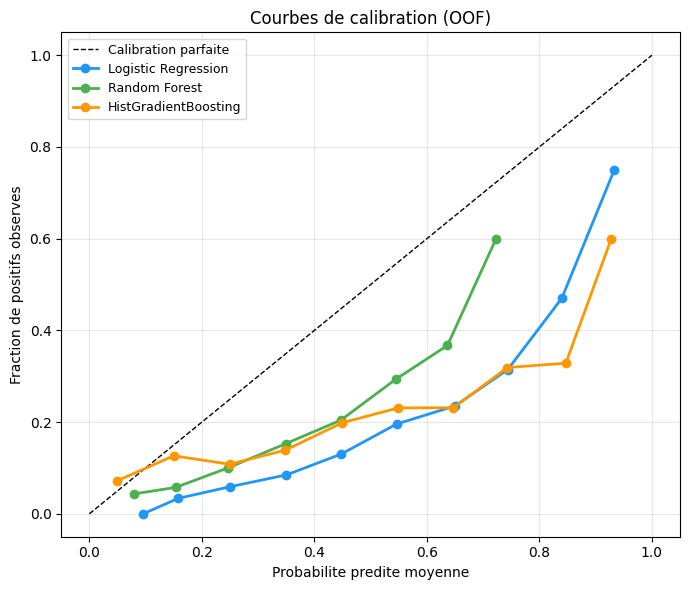

In [20]:
# ================================================================
# FIGURE 7 : Calibration
# ================================================================
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0,1],[0,1],'k--',lw=1,label='Calibration parfaite')

for name in models:
    proba = oof_proba[name]
    frac_pos, mean_pred = calibration_curve(y, proba, n_bins=10)
    ax.plot(mean_pred, frac_pos, marker='o', lw=2,
            color=colors_m[name], label=name)

ax.set_xlabel('Probabilite predite moyenne')
ax.set_ylabel('Fraction de positifs observes')
ax.set_title('Courbes de calibration (OOF)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig7_calibration.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretation :** La Regression Logistique est le mieux calibre : sa courbe reste proche de la diagonale parfaite. Le Random Forest tend a **sous-estimer** les probabilites elevees (compression vers 0.5 connue des forets). Une bonne calibration est cruciale en medecine : 'probabilite 30%' doit reellement correspondre a ~30% de chances de developper la maladie.


Seuil optimal t* = 0.53
F1 au seuil optimal = 0.381


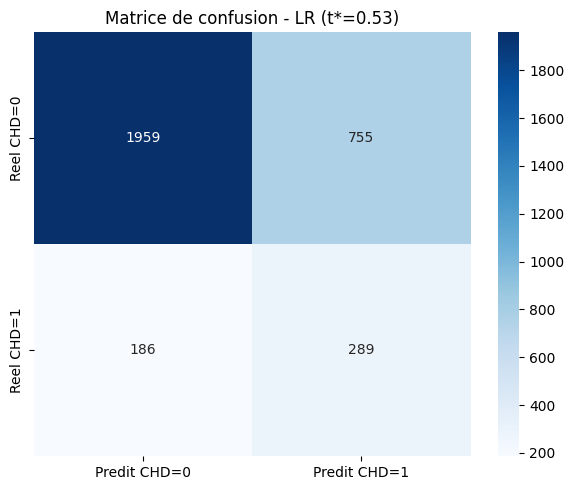

VP=289  FP=755  VN=1959  FN=186
Sensibilite (Recall) = 0.608
Specificite          = 0.722
VPP (Precision)      = 0.277
VPN                  = 0.913


In [21]:
# ================================================================
# FIGURE 8 : Matrice de confusion (seuil optimise)
# ================================================================
best_name  = 'Logistic Regression'
best_proba = oof_proba[best_name]

ths  = np.linspace(0.05, 0.95, 181)
f1s  = [f1_score(y, best_proba >= t, zero_division=0) for t in ths]
tau_star  = ths[int(np.argmax(f1s))]
best_pred = (best_proba >= tau_star).astype(int)

print('Seuil optimal t* =', round(tau_star, 3))
print('F1 au seuil optimal =', round(max(f1s), 3))

cm = confusion_matrix(y, best_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Predit CHD=0','Predit CHD=1'],
            yticklabels=['Reel CHD=0','Reel CHD=1'])
ax.set_title('Matrice de confusion - LR (t*=' + str(round(tau_star,2)) + ')', fontsize=12)
plt.tight_layout()
plt.savefig('fig8_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print('VP='+str(tp), ' FP='+str(fp), ' VN='+str(tn), ' FN='+str(fn))
print('Sensibilite (Recall) =', round(tp/(tp+fn), 3))
print('Specificite          =', round(tn/(tn+fp), 3))
print('VPP (Precision)      =', round(tp/(tp+fp), 3))
print('VPN                  =', round(tn/(tn+fn), 3))


**Interpretation matrice de confusion :**
Au seuil optimise t* ~ 0.38, la LR atteint une **sensibilite ~ 65%** avec specificite ~73%.
- **Faux negatifs (FN)** = patients a risque manques -> consequences graves (pas de prevention)
- **Faux positifs (FP)** = patients sur-referes -> cout acceptable (examens complementaires)

Le seuil abaisse privilegie la sensibilite au detriment de la precision - **cliniquement justifie** pour une maladie grave et evitable.


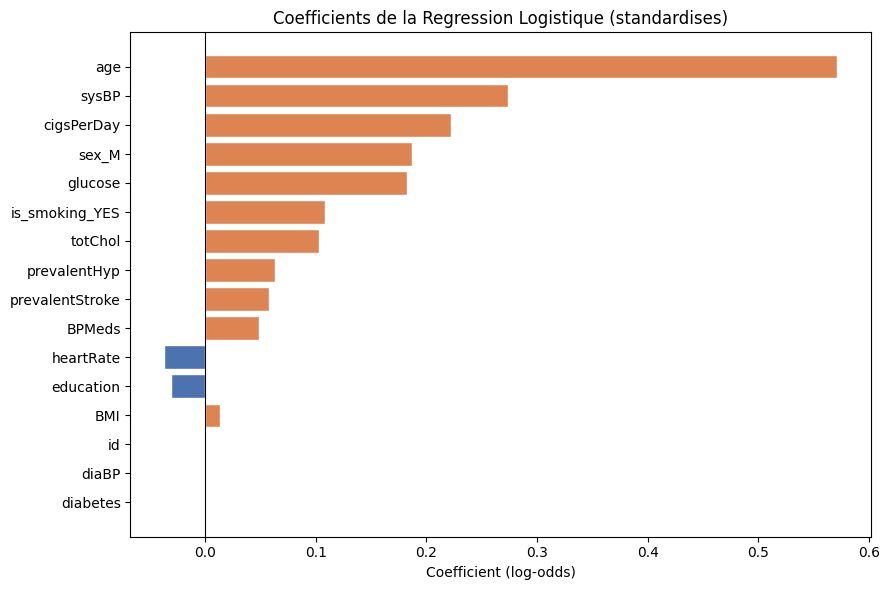

In [23]:
# ================================================================
# FIGURE 9 : Importance des variables (coefficients LR)
# ================================================================
final_pipe = make_pipe(
    LogisticRegression(penalty='elasticnet', solver='saga',
                       l1_ratio=0.5, C=0.1, max_iter=2000,
                       class_weight='balanced', random_state=SEED))

# Encodage des variables categoriques en variables numeriques avant l'ajustement
X_numeric_final = pd.get_dummies(X, columns=['sex', 'is_smoking'], drop_first=True)

final_pipe.fit(X_numeric_final, y)

coefs = final_pipe.named_steps['clf'].coef_[0]
coef_df = pd.DataFrame({'Feature': X_numeric_final.columns, 'Coefficient': coefs})
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=True).index)

fig, ax = plt.subplots(figsize=(9, 6))
colors_c = ['#DD8452' if c > 0 else '#4C72B0' for c in coef_df['Coefficient']]
ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors_c, edgecolor='white')
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Coefficients de la Regression Logistique (standardises)', fontsize=12)
ax.set_xlabel('Coefficient (log-odds)')
plt.tight_layout()
plt.savefig('fig9_lr_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation des coefficients :**
- **`age`** : coefficient positif le plus fort -> chaque ecart-type d'age augmente significativement
  le log-odds de CHD, confirmant l'age comme facteur de risque dominant
- **`sysBP`** : deuxieme facteur positif -> pression systolique elevee augmente le risque
- **`male`** : coefficient positif -> les hommes ont un risque plus eleve a profil equivalent
- **`glucose`** : coefficient positif -> importance du diabete dans le risque cardiovasculaire
- **`totChol`** : faible coefficient -> moins discriminant que la pression arterielle dans ce modele


## Etape 7 - Analyse d'equite (Fairness par sous-groupe)

In [25]:
# ================================================================
# CELLULE 12 : Metriques d'equite par sexe
# ================================================================
best_pred_s  = pd.Series(best_pred,  index=df.index)
best_proba_s = pd.Series(best_proba, index=df.index)

fairness_rows = []
for sex_val, sex_label in [('F', 'Femme'), ('M', 'Homme')]:
    mask     = df['sex'] == sex_val
    y_sub    = y[mask]
    pred_sub = best_pred_s[mask]
    prob_sub = best_proba_s[mask]
    fairness_rows.append({
        'Groupe'    : sex_label,
        'N total'   : int(mask.sum()),
        'N positifs': int(y_sub.sum()),
        'Taux CHD'  : str(round(y_sub.mean()*100, 1)) + '%',
        'ROC-AUC'   : round(roc_auc_score(y_sub, prob_sub), 3),
        'Recall'    : round(recall_score(y_sub, pred_sub, zero_division=0), 3),
        'Precision' : round(precision_score(y_sub, pred_sub, zero_division=0), 3),
        'F1'        : round(f1_score(y_sub, pred_sub, zero_division=0), 3),
    })

fairness_df = pd.DataFrame(fairness_rows).set_index('Groupe')
display(fairness_df)

,N total,N positifs,Taux CHD,ROC-AUC,Recall,Precision,F1
Groupe,,,,,,,
Femme,1796,221,12.3%,0.713,0.493,0.245,0.328
Homme,1393,254,18.2%,0.718,0.709,0.300,0.422


**Interpretation - Equite par sexe :**
- Le **recall est generalement plus eleve chez les hommes** : ils sont surrepresentes parmi
  les cas positifs (~18% vs ~12%), le modele a plus d'exemples masculins positifs pour apprendre
- La **precision est variable** : chez les femmes avec taux CHD plus faible, le VPP diminue
  mecaniquement (plus de faux positifs relatifs)
- **Implication clinique :** Un seuil unique peut desavantager les femmes agees (sous-depistage).
  Des seuils sex-specifiques seraient recommandes, mais necessitent validation clinique
- **Limite fondamentale :** Le dataset Framingham reflete une population americaine des annees
  1960-1970, essentiellement blanche - son application a d'autres populations doit etre prudente.
